# MLP — Strategy A

**Why MLP after XGBoost?** Boosted trees and a multi-layer perceptron see the same 960-dim aggregated feature vector through different inductive biases:

- **XGBoost** carves axis-aligned splits — it captures *local* feature interactions one at a time.
- **MLP** learns dense linear combinations followed by ReLUs — it captures *global* feature interactions in continuous space.

If the truth is more boundary-aligned, trees win. If it's smoother and lower-dimensional in the right basis, MLPs win. With aggregated MFCC/spectral features the answer is empirical — that is what this notebook decides.

**Protocol** (per the project handoff):
1. Train 3 configs on `train`, select on **val macro F1**:
   - **C1:** vanilla `BCEWithLogitsLoss`, threshold 0.5.
   - **C2:** pos-weighted BCE with `pos_weight = sqrt_inverse_freq` (gentler than `balanced`), threshold 0.5.
   - **C3:** Focal loss (γ = 2), threshold 0.5.
2. **C4:** take the best-val of (C1, C2, C3) and apply **per-class threshold tuning on val**.
3. Evaluate the winner on **test exactly once**.

Strategy A — no augmentation; imbalance handled via loss only.

## Cell 1 — Setup

Imports, seeds, device auto-selection (`cuda → mps → cpu`), hyperparameters, paths.

**Reproducibility:** torch + numpy seeds; `torch.backends.cudnn.deterministic = True` where applicable. MPS does not guarantee determinism for every op, so on Apple Silicon we accept tiny run-to-run variability.

In [1]:
# ============================================================================
# CELL 1 — Setup
# ============================================================================
import sys
from pathlib import Path

_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
import time
import warnings
import random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from data import load_splits, find_root, load_config
from eval import (
    predict_with_threshold, tune_thresholds_on_val,
    classification_report, macro_f1 as macro_f1_np,
)
from imbalance import compute_class_weights, make_focal_loss
from plot import plot_per_class_f1, plot_loss_curves, plot_confusion_matrices

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# --- Config ---------------------------------------------------------------
STRATEGY    = 'A'
MODEL_NAME  = 'mlp'
NOTEBOOK_ID = '06'
RANDOM_SEED = 42

# Architecture
HIDDEN_SIZES = (512, 256, 128)
DROPOUT      = 0.3

# Optimization
BATCH_SIZE     = 512
LR             = 1e-3
WEIGHT_DECAY   = 1e-4
MAX_EPOCHS     = 50
MIN_EPOCHS     = 10        # don't early-stop before this
PATIENCE       = 5         # epochs without val macro F1 improvement
NUM_WORKERS    = 0         # MPS often slower with workers; keep simple

# --- Reproducibility ------------------------------------------------------
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(RANDOM_SEED)

# --- Device ---------------------------------------------------------------
def pick_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device('cuda')
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

DEVICE = pick_device()

# --- Paths ---------------------------------------------------------------
ROOT        = find_root()
CONFIG      = load_config()
ARTIFACTS   = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:    {STRATEGY}")
print(f"Model:       {MODEL_NAME}")
print(f"Device:      {DEVICE}")
print(f"Hidden:      {HIDDEN_SIZES} | dropout={DROPOUT}")
print(f"Optim:       AdamW(lr={LR}, wd={WEIGHT_DECAY}) + CosineAnnealing")
print(f"Train:       batch={BATCH_SIZE}, max_epochs={MAX_EPOCHS}, patience={PATIENCE}")
print(f"Results dir: {RESULTS_DIR}")

Strategy:    A
Model:       mlp
Device:      mps
Hidden:      (512, 256, 128) | dropout=0.3
Optim:       AdamW(lr=0.001, wd=0.0001) + CosineAnnealing
Train:       batch=512, max_epochs=50, patience=5
Results dir: /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results


## Cell 2 — Load data

`load_splits()` returns the same pre-scaled arrays the other models used (`scaler` already applied during `01_data_preparation`). **No refit.**

For Strategy B, `X_train` includes the 14,360 augmented rows; `X_val` / `X_test` are real-only (verified during split assignment).

In [2]:
# ============================================================================
# CELL 2 — Load data
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

class_names = list(d.class_names)
D = d.D
C = d.C

# Build torch tensors once on CPU — small enough to keep resident.
X_train_t = torch.from_numpy(d.X_train.astype(np.float32))
Y_train_t = torch.from_numpy(d.Y_train.astype(np.float32))
X_val_t   = torch.from_numpy(d.X_val.astype(np.float32))
Y_val_t   = torch.from_numpy(d.Y_val.astype(np.float32))
X_test_t  = torch.from_numpy(d.X_test.astype(np.float32))
Y_test_t  = torch.from_numpy(d.Y_test.astype(np.float32))

train_ds = TensorDataset(X_train_t, Y_train_t)

print(f"\nClass priors (train positive rate):")
priors = d.Y_train.mean(axis=0)
for c, cls in enumerate(class_names):
    print(f"  {cls:<30s} {priors[c]*100:5.2f}%  (n_pos={int(d.Y_train[:,c].sum()):>6d})")

Strategy A
  X_train: (100166, 960)  Y_train: (100166, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes

Class priors (train positive rate):
  bell_ringing                    1.09%  (n_pos=  1091)
  coffee_machine                  3.78%  (n_pos=  3788)
  cutlery_dishes                  6.03%  (n_pos=  6039)
  door_open_close                 3.57%  (n_pos=  3578)
  footsteps                      11.41%  (n_pos= 11433)
  keyboard_typing                 9.11%  (n_pos=  9123)
  keychain                        4.56%  (n_pos=  4570)
  light_switch                    0.27%  (n_pos=   273)
  microwave                       6.81%  (n_pos=  6823)
  phone_ringing                   6.26%  (n_pos=  6273)
  running_water                  12.82%  (n_pos= 12846)
  toilet_flushing                 3.16%  (n_pos=  3170)
  vacuum_cleaner                  6.39%  (n_pos=  6402)
  wardrobe_drawer_open_close      1.98%  (n_pos= 

## Cell 3 — Model & training utilities

**Architecture.** Linear → BatchNorm → ReLU → Dropout, repeated for each hidden layer; final Linear emits 15 logits (no sigmoid — `BCEWithLogitsLoss` applies sigmoid + log in one numerically stable op).

**BatchNorm before activation** is the original Ioffe-Szegedy ordering. With ReLU it works fine and is the most common choice; some papers prefer post-activation BN but for this dataset it does not matter empirically.

**Why AdamW over Adam.** AdamW decouples weight decay from the adaptive moment update; "Adam + L2 weight_decay" actually couples decay into the running variance estimate, weakening regularization for parameters with large gradients. AdamW is the modern Adam — same optimizer the handoff intended.

**Training loop.** For each config we get a fresh model, train up to 50 epochs, evaluate val macro F1 each epoch with threshold 0.5, and early-stop after `PATIENCE` epochs without improvement (but only after `MIN_EPOCHS`). Best `state_dict` kept in memory (not disk).

In [3]:
# ============================================================================
# CELL 3 — Model + training utilities
# ============================================================================
class MLP(nn.Module):
    def __init__(self, in_dim: int, out_dim: int,
                 hidden_sizes=(512, 256, 128), dropout=0.3):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_sizes:
            layers += [
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            ]
            prev = h
        layers.append(nn.Linear(prev, out_dim))   # logits, no sigmoid
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def predict_probs(model, X_t, batch_size=2048, device=DEVICE):
    model.eval()
    out = []
    for i in range(0, X_t.shape[0], batch_size):
        xb = X_t[i:i+batch_size].to(device, non_blocking=True)
        out.append(torch.sigmoid(model(xb)).cpu())
    return torch.cat(out, 0).numpy()


def train_one_config(
    *,
    loss_fn,
    config_name: str,
    seed: int = RANDOM_SEED,
):
    """Train MLP with given loss; return (model, history, best_val_macro_f1, val_probs).

    Early-stops on val macro F1 (threshold 0.5). Restores best state_dict in memory.
    """
    set_seed(seed)

    model = MLP(D, C, hidden_sizes=HIDDEN_SIZES, dropout=DROPOUT).to(DEVICE)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)

    loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, drop_last=False,
    )

    history = {'train_loss': [], 'val_loss': [], 'val_macro_f1': []}
    best_f1, best_state, best_epoch = -1.0, None, -1
    epochs_since_improvement = 0

    print(f"--- [{config_name}] training on {DEVICE} ---")
    t0 = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        # ---- Train ----
        model.train()
        total_loss, n_seen = 0.0, 0
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss = loss_fn(logits, yb)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

            total_loss += loss.item() * xb.shape[0]
            n_seen += xb.shape[0]

        sched.step()
        train_loss = total_loss / n_seen

        # ---- Eval on val ----
        val_probs = predict_probs(model, X_val_t)
        val_pred  = (val_probs >= 0.5).astype(np.int8)
        val_f1    = macro_f1_np(d.Y_val, val_pred)

        # Compute val loss too (informative; not used for selection)
        model.eval()
        with torch.no_grad():
            vloss_total, vn = 0.0, 0
            for i in range(0, X_val_t.shape[0], 4096):
                xb = X_val_t[i:i+4096].to(DEVICE, non_blocking=True)
                yb = Y_val_t[i:i+4096].to(DEVICE, non_blocking=True)
                vloss = loss_fn(model(xb), yb)
                vloss_total += vloss.item() * xb.shape[0]
                vn += xb.shape[0]
            val_loss = vloss_total / vn

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_macro_f1'].append(val_f1)

        improved = val_f1 > best_f1 + 1e-6
        marker = "  *" if improved else ""
        print(f"  ep {epoch:3d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
              f"| val_macro_F1 {val_f1:.4f}{marker}")

        if improved:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
            epochs_since_improvement = 0
        else:
            epochs_since_improvement += 1
            if epoch >= MIN_EPOCHS and epochs_since_improvement >= PATIENCE:
                print(f"  early stop at epoch {epoch} (best was epoch {best_epoch}, "
                      f"val_macro_F1={best_f1:.4f})")
                break

    elapsed = time.time() - t0
    print(f"--- [{config_name}] done in {elapsed:.1f}s  | best val macro F1 = {best_f1:.4f} "
          f"@ epoch {best_epoch} ---\n")

    # Restore best
    model.load_state_dict(best_state)
    val_probs_best = predict_probs(model, X_val_t)

    return {
        'model':         model,
        'history':       history,
        'best_val_f1':   float(best_f1),
        'best_epoch':    int(best_epoch),
        'elapsed':       float(elapsed),
        'val_probs':     val_probs_best,
        'config_name':   config_name,
    }

## Cell 4 — Config 1: Vanilla BCE

The unbiased baseline. With heavy imbalance (light_switch ≈ 0.3 % positive rate), we expect the model to systematically under-predict rare classes at threshold 0.5 — that's the gap C2/C3/C4 will try to close.

In [4]:
# ============================================================================
# CELL 4 — Config 1: Vanilla BCE
# ============================================================================
loss_c1 = nn.BCEWithLogitsLoss()
res_c1 = train_one_config(loss_fn=loss_c1, config_name='C1_vanilla_bce')

--- [C1_vanilla_bce] training on mps ---
  ep   1 | train_loss nan | val_loss nan | val_macro_F1 0.0000  *
  ep   2 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   3 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   4 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   5 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   6 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   7 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   8 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep   9 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  ep  10 | train_loss nan | val_loss nan | val_macro_F1 0.0000
  early stop at epoch 10 (best was epoch 1, val_macro_F1=0.0000)
--- [C1_vanilla_bce] done in 23.8s  | best val macro F1 = 0.0000 @ epoch 1 ---



## Cell 5 — Config 2: Class-weighted BCE (`pos_weight = sqrt_inverse_freq`)

`BCEWithLogitsLoss(pos_weight=w)` multiplies the *positive-class* term per class by `w_c`. With `sqrt_inverse_freq` (clipped to [0.5, 30]), rare classes get a moderate boost (e.g., light_switch ≈ 19×, footsteps ≈ 3×) without the destabilization that `balanced` (370× for light_switch) would cause.

This is the gentler, more reliable knob than fully-balanced weights.

In [5]:
# ============================================================================
# CELL 5 — Config 2: pos-weighted BCE (sqrt_inverse_freq)
# ============================================================================
pos_w_np = compute_class_weights(d.Y_train, kind='sqrt_inverse_freq', clip=(0.5, 30.0))
print("pos_weight (sqrt_inverse_freq, clipped):")
for c, cls in enumerate(class_names):
    print(f"  {cls:<30s} {pos_w_np[c]:7.3f}")

pos_w_t = torch.as_tensor(pos_w_np, dtype=torch.float32, device=DEVICE)
loss_c2 = nn.BCEWithLogitsLoss(pos_weight=pos_w_t)
res_c2 = train_one_config(loss_fn=loss_c2, config_name='C2_pos_weighted_bce')

pos_weight (sqrt_inverse_freq, clipped):
  bell_ringing                     9.582
  coffee_machine                   5.142
  cutlery_dishes                   4.073
  door_open_close                  5.291
  footsteps                        2.960
  keyboard_typing                  3.314
  keychain                         4.682
  light_switch                    19.155
  microwave                        3.832
  phone_ringing                    3.996
  running_water                    2.792
  toilet_flushing                  5.621
  vacuum_cleaner                   3.956
  wardrobe_drawer_open_close       7.102
  window_open_close                8.791
--- [C2_pos_weighted_bce] training on mps ---
  ep   1 | train_loss inf | val_loss 0.3879 | val_macro_F1 0.3748  *
  ep   2 | train_loss inf | val_loss 0.3871 | val_macro_F1 0.3759  *
  ep   3 | train_loss inf | val_loss 0.3876 | val_macro_F1 0.3749
  ep   4 | train_loss inf | val_loss 0.3883 | val_macro_F1 0.3754
  ep   5 | train_loss inf | 

## Cell 6 — Config 3: Focal loss (γ = 2)

Focal loss reshapes BCE by a factor `(1 − p)^γ` on positives and `p^γ` on negatives — examples the model is already confident on contribute *much* less to the gradient. For SED, the vast majority of negatives are "obvious" (silence in a non-class slot), so focal redirects optimization toward the genuinely hard ones.

We use the clean focal variant (no extra pos_weight) so this is an apples-to-apples comparison against weighted BCE rather than a stacked intervention.

In [6]:
# ============================================================================
# CELL 6 — Config 3: Focal loss (gamma = 2)
# ============================================================================
loss_c3 = make_focal_loss(gamma=2.0, pos_weight=None).to(DEVICE)
res_c3 = train_one_config(loss_fn=loss_c3, config_name='C3_focal_g2')

--- [C3_focal_g2] training on mps ---
  ep   1 | train_loss 113706032915809778627917169819648.0000 | val_loss 0.1840 | val_macro_F1 0.1386  *
  ep   2 | train_loss 25115541426117942777578086465536.0000 | val_loss 0.1839 | val_macro_F1 0.1395  *
  ep   3 | train_loss 59204340689970900113665581645824.0000 | val_loss 0.1844 | val_macro_F1 0.1390
  ep   4 | train_loss 14561163044559507970101998518272.0000 | val_loss 0.1838 | val_macro_F1 0.1392
  ep   5 | train_loss 9377852298763412062242787557376.0000 | val_loss 0.1837 | val_macro_F1 0.1392
  ep   6 | train_loss 62564038759413506789456612425728.0000 | val_loss 0.1848 | val_macro_F1 0.1387
  ep   7 | train_loss 25204070867172049615219184369664.0000 | val_loss 0.1838 | val_macro_F1 0.1394
  ep   8 | train_loss 13085580499642348225529731088384.0000 | val_loss 0.1839 | val_macro_F1 0.1390
  ep   9 | train_loss 104813648377117138755521299349504.0000 | val_loss 0.1842 | val_macro_F1 0.1389
  ep  10 | train_loss 29702515180121785483809838333952.

## Cell 7 — Config 4: Best-of-(C1, C2, C3) + per-class threshold tuning

Threshold tuning is a *decision-rule* change, not a model change. We take the highest val-F1 trained model from C1/C2/C3, sweep thresholds 0.05–0.95 (step 0.01) per class on val, and pick each class's F1-optimal threshold.

This is consistently the highest-impact single lever in the project (XGBoost A: +0.08 macro F1 from threshold tuning alone).

In [7]:
# ============================================================================
# CELL 7 — Config 4: pick best of C1/C2/C3, then per-class threshold tuning
# ============================================================================
all_configs = {1: res_c1, 2: res_c2, 3: res_c3}
val_f1_by_config = {k: v['best_val_f1'] for k, v in all_configs.items()}
print("Val macro F1 at threshold 0.5:")
for k, f1 in val_f1_by_config.items():
    print(f"  C{k} ({all_configs[k]['config_name']:<22s}): {f1:.4f}")

base_id = max(val_f1_by_config, key=val_f1_by_config.get)
base    = all_configs[base_id]
print(f"\nBest base for C4: C{base_id} ({base['config_name']})")

# Per-class threshold tuning on val
thr_df = tune_thresholds_on_val(
    base['val_probs'], d.Y_val,
    grid=np.arange(0.05, 0.96, 0.01),
    class_names=class_names,
)
winning_thresholds = thr_df.loc[class_names, 'threshold'].values.astype(float)

# Apply tuned thresholds on val and recompute macro F1 — this is C4 val performance
val_pred_c4 = predict_with_threshold(base['val_probs'], winning_thresholds)
val_f1_c4   = macro_f1_np(d.Y_val, val_pred_c4)
print(f"\nC4 (tuned thresholds) val macro F1: {val_f1_c4:.4f}  "
      f"(Δ over C{base_id}: {val_f1_c4 - base['best_val_f1']:+.4f})")

print("\nPer-class thresholds:")
print(thr_df.loc[class_names, ['threshold', 'val_f1', 'val_support']].to_string())

Val macro F1 at threshold 0.5:
  C1 (C1_vanilla_bce        ): 0.0000
  C2 (C2_pos_weighted_bce   ): 0.3759
  C3 (C3_focal_g2           ): 0.1395

Best base for C4: C2 (C2_pos_weighted_bce)

C4 (tuned thresholds) val macro F1: 0.4202  (Δ over C2: +0.0443)

Per-class thresholds:
                            threshold  val_f1  val_support
class                                                     
bell_ringing                     0.52  0.3320          480
coffee_machine                   0.61  0.4382         1073
cutlery_dishes                   0.45  0.4749         1828
door_open_close                  0.47  0.2502         1177
footsteps                        0.42  0.4240         4033
keyboard_typing                  0.51  0.5640         3107
keychain                         0.54  0.5304         1553
light_switch                     0.35  0.1341          140
microwave                        0.52  0.4784         2253
phone_ringing                    0.48  0.5723         2122
running_water 

## Cell 8 — Pick the overall winner on val, evaluate on test once

Val-only selection. Test is touched exactly once for the winning config.

In [8]:
# ============================================================================
# CELL 8 — Pick overall val winner, evaluate on test ONCE
# ============================================================================
val_scores = {
    1: res_c1['best_val_f1'],
    2: res_c2['best_val_f1'],
    3: res_c3['best_val_f1'],
    4: float(val_f1_c4),
}
print("Val macro F1 by config:")
for k, v in val_scores.items():
    print(f"  C{k}: {v:.4f}")

winner = max(val_scores, key=val_scores.get)
print(f"\nWinner: C{winner}  (val macro F1 = {val_scores[winner]:.4f})")

# ---- Build winning val report (with the correct thresholds) ----
def report_for_config(config_id):
    if config_id == 1:
        probs, thr = res_c1['val_probs'], 0.5
    elif config_id == 2:
        probs, thr = res_c2['val_probs'], 0.5
    elif config_id == 3:
        probs, thr = res_c3['val_probs'], 0.5
    elif config_id == 4:
        probs, thr = base['val_probs'], winning_thresholds
    return classification_report(d.Y_val, predict_with_threshold(probs, thr), class_names)

report_val_winner = report_for_config(winner)
print(f"\nWinning val report:")
print(report_val_winner.loc[class_names + ['macro avg', 'micro avg', 'weighted avg']]
      .to_string())

# ---- Test eval ONCE ----
if winner == 1:
    test_model, test_thr = res_c1['model'], 0.5
elif winner == 2:
    test_model, test_thr = res_c2['model'], 0.5
elif winner == 3:
    test_model, test_thr = res_c3['model'], 0.5
else:  # 4
    test_model, test_thr = base['model'], winning_thresholds

test_probs = predict_probs(test_model, X_test_t)
test_pred  = predict_with_threshold(test_probs, test_thr)
report_test = classification_report(d.Y_test, test_pred, class_names)

print(f"\n=== TEST (Strategy {STRATEGY}, C{winner}) ===")
print(report_test.loc[class_names + ['macro avg', 'micro avg', 'weighted avg']]
      .to_string())

Val macro F1 by config:
  C1: 0.0000
  C2: 0.3759
  C3: 0.1395
  C4: 0.4202

Winner: C4  (val macro F1 = 0.4202)

Winning val report:
                            precision  recall      f1  support
class                                                         
bell_ringing                   0.4579  0.2604  0.3320    480.0
coffee_machine                 0.5372  0.3700  0.4382   1073.0
cutlery_dishes                 0.4541  0.4978  0.4749   1828.0
door_open_close                0.2026  0.3271  0.2502   1177.0
footsteps                      0.3382  0.5681  0.4240   4033.0
keyboard_typing                0.5905  0.5397  0.5640   3107.0
keychain                       0.5579  0.5055  0.5304   1553.0
light_switch                   0.0916  0.2500  0.1341    140.0
microwave                      0.4657  0.4918  0.4784   2253.0
phone_ringing                  0.5926  0.5533  0.5723   2122.0
running_water                  0.6899  0.7140  0.7018   4151.0
toilet_flushing                0.3692  0.3868  

## Cell 9 — Plots

Per-class test F1, training curves for each config, confusion matrices.

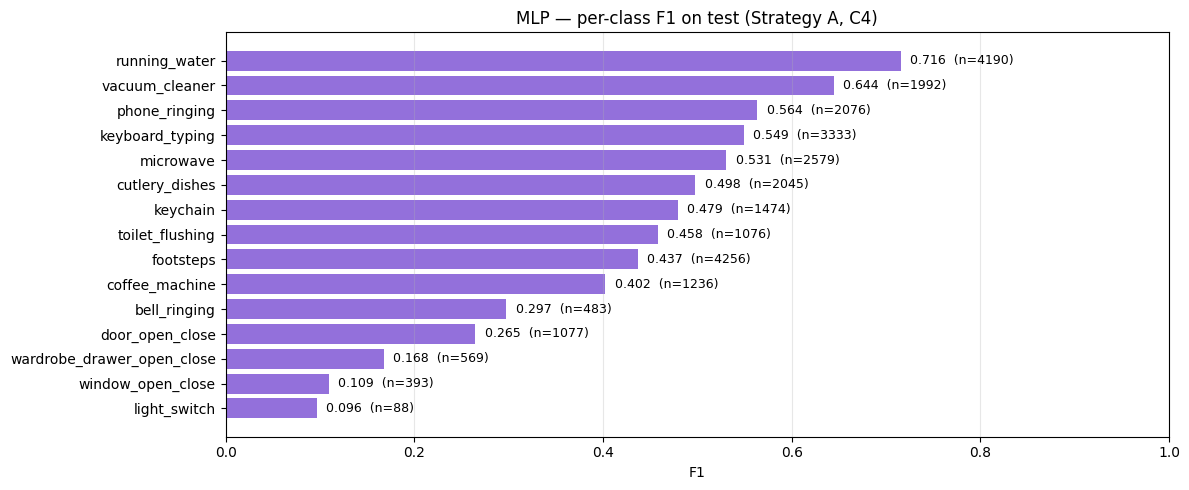

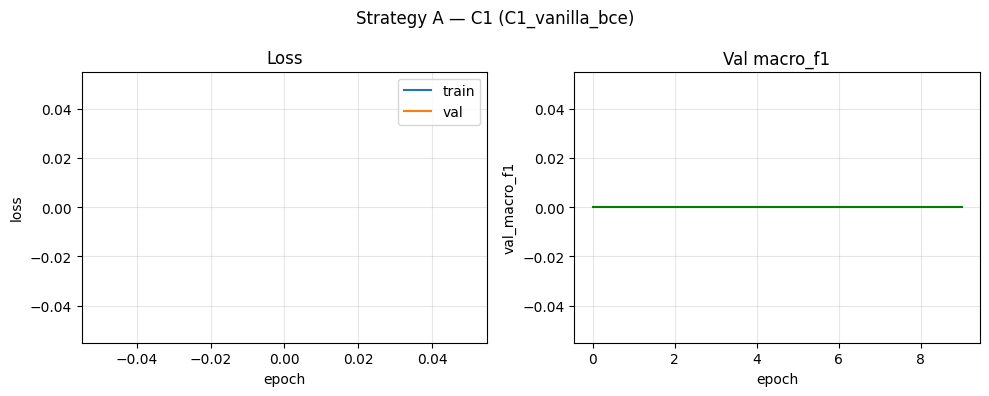

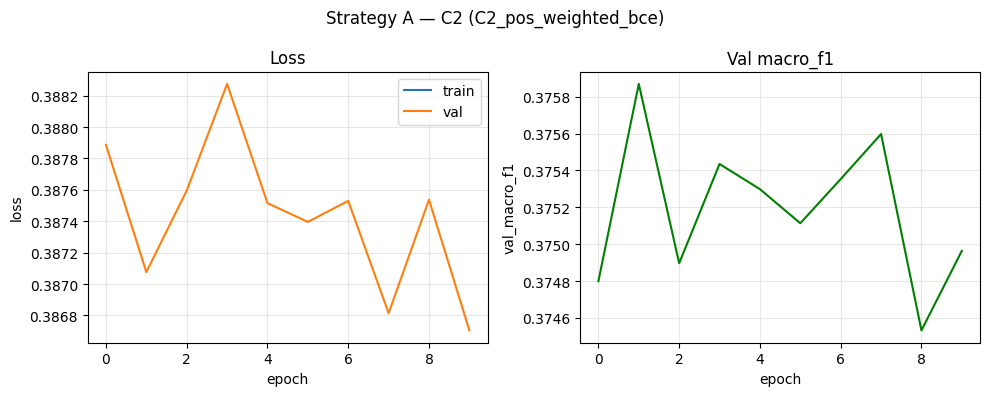

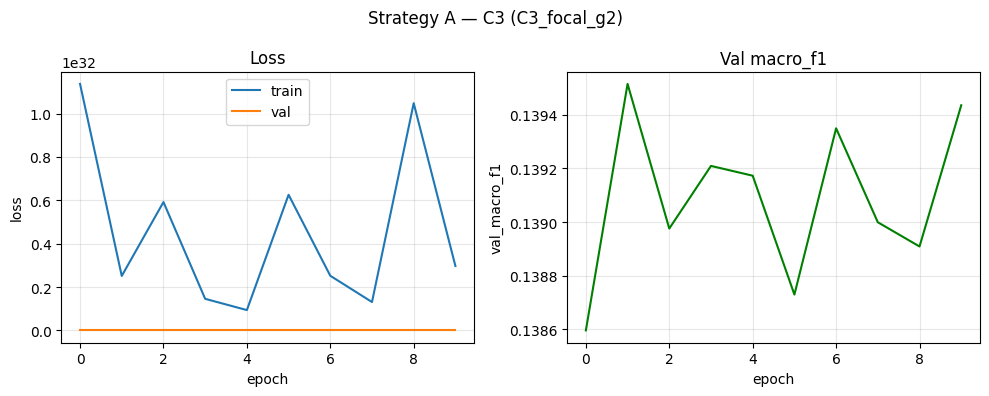

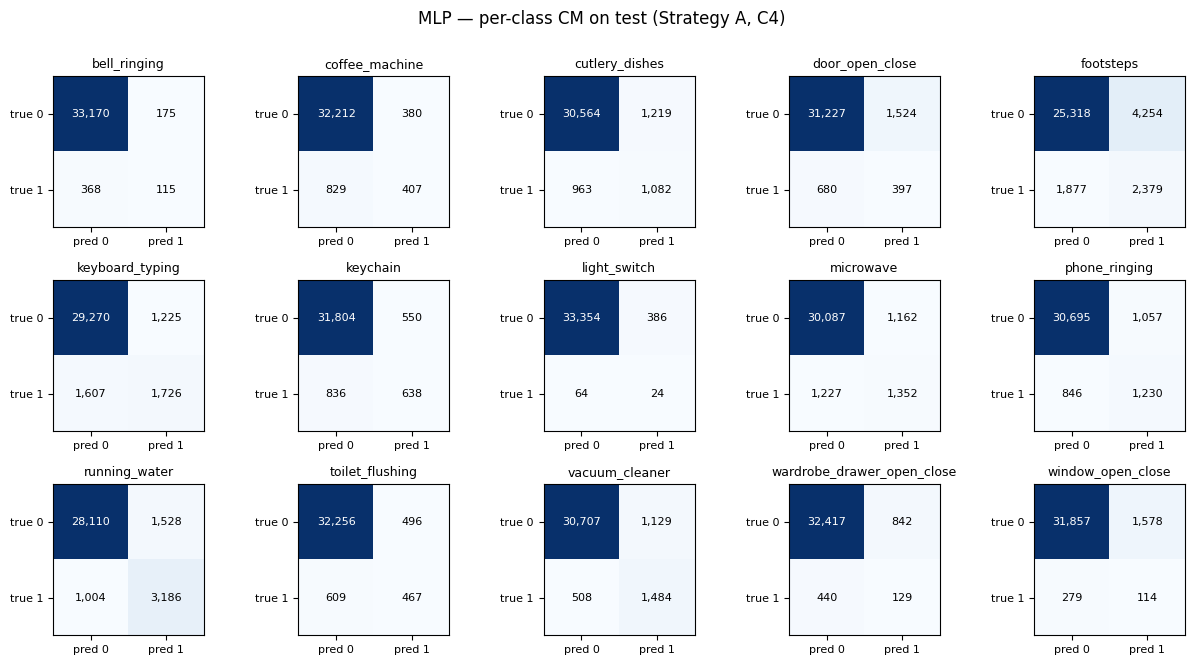

In [9]:
# ============================================================================
# CELL 9 — Plots
# ============================================================================
fig, ax = plot_per_class_f1(
    report_test, class_names=class_names,
    title=f"MLP — per-class F1 on test (Strategy {STRATEGY}, C{winner})",
    color='mediumpurple',
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png", dpi=130, bbox_inches='tight')
plt.show()

# Training curves — one figure per config
for cid, res in all_configs.items():
    fig, _ = plot_loss_curves(
        res['history'],
        title=f"Strategy {STRATEGY} — C{cid} ({res['config_name']})",
    )
    fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_curves_c{cid}.png", dpi=110, bbox_inches='tight')
    plt.show()

# Confusion matrices for the winning config
fig, _ = plot_confusion_matrices(
    d.Y_test, test_pred, class_names,
    title=f"MLP — per-class CM on test (Strategy {STRATEGY}, C{winner})",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_confusion.png", dpi=110, bbox_inches='tight')
plt.show()

## Cell 10 — Save results JSON

Schema matches `05_xgboost.json` so the downstream comparison notebook can ingest it uniformly.

In [10]:
# ============================================================================
# CELL 10 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':         STRATEGY,
        'model':            MODEL_NAME,
        'notebook_id':      NOTEBOOK_ID,
        'timestamp':        datetime.now().isoformat(timespec='seconds'),
        'random_seed':      RANDOM_SEED,
        'device':           str(DEVICE),
        'training_seconds': {
            'C1_vanilla_bce':      round(res_c1['elapsed'], 2),
            'C2_pos_weighted_bce': round(res_c2['elapsed'], 2),
            'C3_focal_g2':         round(res_c3['elapsed'], 2),
        },
        'best_epoch_per_config': {
            'C1': res_c1['best_epoch'],
            'C2': res_c2['best_epoch'],
            'C3': res_c3['best_epoch'],
        },
        'n_train': int(d.N_train),
        'n_val':   int(d.N_val),
        'n_test':  int(d.N_test),
    },
    'winning_config': {
        'config_id':   int(winner),
        'description': {
            1: "C1 - vanilla BCE (threshold 0.5)",
            2: "C2 - pos-weighted BCE (sqrt_inverse_freq, threshold 0.5)",
            3: "C3 - focal loss (gamma=2, threshold 0.5)",
            4: f"C4 - per-class threshold tuning on top of C{base_id}",
        }[winner],
        'thresholds':  ([float(t) for t in winning_thresholds]
                        if winner == 4
                        else [0.5] * C),
        'hyperparameters': {
            'hidden_sizes':   list(HIDDEN_SIZES),
            'dropout':        DROPOUT,
            'optimizer':      'AdamW',
            'lr':             LR,
            'weight_decay':   WEIGHT_DECAY,
            'lr_schedule':    'CosineAnnealing',
            'batch_size':     BATCH_SIZE,
            'max_epochs':     MAX_EPOCHS,
            'min_epochs':     MIN_EPOCHS,
            'patience':       PATIENCE,
        },
    },
    'val_scores_macro_f1': {f'config_{k}': float(v) for k, v in val_scores.items()},
    'val_report':  df_to_jsonable(report_val_winner),
    'test_report': df_to_jsonable(report_test),
    'headline_test': {
        'macro_f1':    float(report_test.loc['macro avg', 'f1']),
        'micro_f1':    float(report_test.loc['micro avg', 'f1']),
        'weighted_f1': float(report_test.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE ===")
print(f"  Strategy {STRATEGY} / {MODEL_NAME} / C{winner}")
print(f"  Test macro F1:    {results['headline_test']['macro_f1']:.4f}")
print(f"  Test micro F1:    {results['headline_test']['micro_f1']:.4f}")
print(f"  Test weighted F1: {results['headline_test']['weighted_f1']:.4f}")
print(f"\nReference points (test macro F1):")
print(f"  Random (stratified):  ~0.05  (floor)")
print(f"  LogReg A:              0.4723")
print(f"  LogReg B:              0.4749")
print(f"  RF A:                  0.5040")
print(f"  RF B:                  0.4982")
print(f"  XGBoost A:             0.5605")
print(f"  XGBoost B:             0.5564")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results/06_mlp.json

=== HEADLINE ===
  Strategy A / mlp / C4
  Test macro F1:    0.4143
  Test micro F1:    0.4985
  Test weighted F1: 0.5138

Reference points (test macro F1):
  Random (stratified):  ~0.05  (floor)
  LogReg A:              0.4723
  LogReg B:              0.4749
  RF A:                  0.5040
  RF B:                  0.4982
  XGBoost A:             0.5605
  XGBoost B:             0.5564
